# 06 · Replication
**Track B**: city hold-out (INTERNAL_REPLICATION). **Track A**: spleen vs skin from the **same animals** (CROSS_TISSUE_SAME_COHORT): a consistency check, never independent replication.

In [1]:
import json, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from synera_core.config import find_repo_root, get_settings
warnings.filterwarnings("ignore")
ROOT = find_repo_root()
C = dict(bg="#061424", panel="#0b2037", cyan="#16B5FF", green="#6FD65B", amber="#FFB547", red="#FF4D5E", teal="#19E3B1", text="#EAF2FB", muted="#8FA6BF")
plt.rcParams.update({"figure.facecolor": C["bg"], "axes.facecolor": C["bg"], "axes.edgecolor": C["muted"], "axes.labelcolor": C["text"],
    "text.color": C["text"], "xtick.color": C["muted"], "ytick.color": C["muted"], "grid.color": "#1c3a5c", "axes.grid": True, "grid.linewidth": 0.5,
    "axes.prop_cycle": plt.cycler(color=[C["cyan"], C["green"], C["amber"], C["red"], C["teal"]]), "figure.dpi": 110, "font.size": 9})
SEED = get_settings().seeds.global_seed
RES = ROOT / "artifacts" / "results"

In [2]:
from synera_core.pipeline import track_a as TA
e1, m1 = TA.load_study("OSD-211"); e2, m2 = TA.load_study("OSD-237")
r1, r2 = TA.interaction_table(e1, m1), TA.interaction_table(e2, m2)
cons = TA.cross_tissue_consistency(r1, r2, m1, m2)
print(json.dumps({k: cons[k] for k in ["evidence_level","animals_shared","animals_discovery","genes_shared_after_filter","fdr_hits_discovery","fdr_hits_replication",
  "exploratory_top100_sign_concordance","interaction_effect_spearman_rho_all_shared_genes"]}, indent=1)); print(cons["caveat"]); print(cons["interpretation"])

{
 "evidence_level": "CROSS_TISSUE_SAME_COHORT",
 "animals_shared": 20,
 "animals_discovery": 21,
 "genes_shared_after_filter": 22636,
 "fdr_hits_discovery": 0,
 "fdr_hits_replication": 0,
 "exploratory_top100_sign_concordance": 0.55,
 "interaction_effect_spearman_rho_all_shared_genes": 0.01793875457069088
}
Same animals contributed both tissues; this is a consistency check, not independent replication.
No gene passes FDR in either tissue, so no gene is replicated. The numbers describe agreement of the exploratory ranking between tissues only.


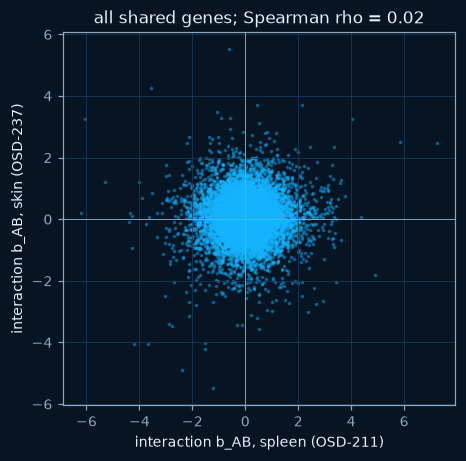

In [3]:
j = r1.join(r2, lsuffix="_spleen", rsuffix="_skin", how="inner")
fig, ax = plt.subplots(figsize=(4.6, 4.4)); ax.scatter(j.b_AB_spleen, j.b_AB_skin, s=2, c=C["cyan"], alpha=0.35)
ax.axhline(0, color=C["muted"], lw=0.6); ax.axvline(0, color=C["muted"], lw=0.6); ax.set_xlabel("interaction b_AB, spleen (OSD-211)"); ax.set_ylabel("interaction b_AB, skin (OSD-237)")
ax.set_title(f"all shared genes; Spearman rho = {cons['interaction_effect_spearman_rho_all_shared_genes']:.2f}"); plt.show()

In [4]:
from synera_core.pipeline.orchestrator import _holdout_replication, default_params
from synera_core.pipeline.registry import get_spec, load_panel
from synera_core.discovery.stack import run_full_stack
from synera_core.benchmark.generator import STRESSORS
params = default_params("benchmark_track_b", quick=True)
df = load_panel(get_spec("benchmark_track_b"))
res = run_full_stack(df, "outcome", STRESSORS, n_boot=params["n_boot"], n_ci=params["n_ci"], seed=params["seed"])
acc = [p for p in res["pairs"] if p["s3_conditional"]]
hold = _holdout_replication(df, acc, params)
pd.DataFrame([{"pair": f"{a} x {b}", "half A p": v["halves"]["A"]["p"], "half B p": v["halves"]["B"]["p"], "replicated": v["replicated"]} for (a, b), v in hold.items()])

,pair,half A p,half B p,replicated
0,heat_index x pm25,1.233231e-45,1.031112e-38,True
1,heat_index x rh,4.205742e-44,8.954843e-38,False
2,heat_index x o3,7.182554e-08,1.689568e-07,True
